# GE2340 Group 26 · Train the lost-and-found matcher

This notebook trains the model used by the local web app. Umbrella photos are no longer in the category list or the training set.

Use **Run All**. The steps write fresh files into `artifacts/`, then show the metrics table and graphs in this notebook. After training, restart the web app with `python app/server.py`.

## 1. Setup

Select this project's Python environment as the notebook kernel, then run the next cell once to install all required libraries into that environment.

In [1]:
%pip install numpy pandas pillow scikit-learn matplotlib certifi ipykernel torch torchvision open-clip-torch ftfy regex tqdm huggingface_hub safetensors timm tiktoken


Note: you may need to restart the kernel to use updated packages.


In [2]:
from __future__ import annotations

from collections import Counter
from pathlib import Path

import numpy as np

from src.campus import location_closeness, time_closeness
from src.pipeline import (
    ROOT,
    SEED,
    SOURCES,
    build_queries,
    build_records,
    classification_report as project_classification_report,
    dump_json,
    evaluate,
    fit_linear_matcher,
    metadata_arrays,
    oracle_scores,
    print_table,
    random_summary,
    save_figures,
    top_case,
    train_heads,
    tune_fusion,
    write_findings,
)
from src.scoring import clip_fusion, linear_probability
from src.vision import CATEGORIES, COLOURS, DISPLAY_CATEGORY, ClipEncoder, CnnEncoder, text_prompt

print('Project folder:', ROOT)
print('Categories:', CATEGORIES)
assert 'umbrella' not in CATEGORIES, 'umbrella should not be used for training'


Project folder: /Users/soshinghin/Desktop/ge2340-lost-found-main 2
Categories: ['key', 'bottle', 'earphone', 'laptop', 'watch']


## 2. Sample photos and simulate campus reports

In [3]:
rng = np.random.default_rng(SEED)
art = ROOT / 'artifacts'
thumb_dir = art / 'thumbs'
thumb_dir.mkdir(parents=True, exist_ok=True)

print('Sampling photos and simulating campus reports...')
records = build_records(rng, thumb_dir)
print('Records:', len(records))
print('Colours:', dict(Counter(record['colour'] for record in records)))
print('Categories:', dict(Counter(record['category'] for record in records)))
assert 'umbrella' not in {record['category'] for record in records}

val_queries = build_queries(records, 'val', rng)
test_queries = build_queries(records, 'test', rng)
gallery = [record for record in records if record['split'] != 'train']
gallery.sort(key=lambda record: record['id'])
record_index = {record['id']: index for index, record in enumerate(records)}
train_index = np.array([index for index, record in enumerate(records) if record['split'] == 'train'])
gallery_index = np.array([record_index[record['id']] for record in gallery])
print('Gallery:', len(gallery), 'val queries:', len(val_queries), 'test queries:', len(test_queries))


Sampling photos and simulating campus reports...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Records: 716
Colours: {'gray': 341, 'brown': 41, 'orange': 23, 'yellow': 8, 'blue': 70, 'green': 12, 'red': 9, 'black': 165, 'white': 31, 'pink': 7, 'purple': 9}
Categories: {'bottle': 172, 'key': 72, 'earphone': 120, 'laptop': 180, 'watch': 172}
Gallery: 298 val queries: 149 test queries: 149


## 3. Train the frozen-CNN linear heads

In [4]:
import os
import ssl
import certifi

ca_bundle = certifi.where()
os.environ["SSL_CERT_FILE"] = ca_bundle
os.environ["REQUESTS_CA_BUNDLE"] = ca_bundle

# Make urllib, used by torchvision, use certifi's trusted certificates.
ssl._create_default_https_context = lambda: ssl.create_default_context(
    cafile=ca_bundle
)
import os
import ssl
import certifi
import urllib.request

ca_file = certifi.where()
os.environ["SSL_CERT_FILE"] = ca_file
os.environ["REQUESTS_CA_BUNDLE"] = ca_file

def certifi_context(*args, **kwargs):
    kwargs["cafile"] = ca_file
    return ssl.create_default_context(*args, **kwargs)

ssl._create_default_https_context = certifi_context
urllib.request._opener = None  # rebuild urllib's HTTPS opener



In [5]:
print('Encoding frozen MobileNet features...')
cnn = CnnEncoder()
cnn_features = cnn.encode_images([ROOT / record['source_rel'] for record in records])
scaler, category_model, colour_model, pred_category, pred_colour = train_heads(
    cnn_features, records, train_index, gallery_index
)
for record, category, colour in zip(gallery, pred_category, pred_colour):
    record['pred_category'] = str(category)
    record['pred_colour'] = str(colour)
    record['pred_category_label'] = DISPLAY_CATEGORY[str(category)]
print('Trained category and colour softmax heads')


Encoding frozen MobileNet features...
Loaded MobileNetV3-Small (ImageNet, frozen)
  CNN features 16/716
  CNN features 32/716
  CNN features 48/716
  CNN features 64/716
  CNN features 80/716
  CNN features 96/716
  CNN features 112/716
  CNN features 128/716
  CNN features 144/716
  CNN features 160/716
  CNN features 176/716
  CNN features 192/716
  CNN features 208/716
  CNN features 224/716
  CNN features 240/716


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  CNN features 256/716
  CNN features 272/716
  CNN features 288/716
  CNN features 304/716
  CNN features 320/716
  CNN features 336/716
  CNN features 352/716
  CNN features 368/716
  CNN features 384/716
  CNN features 400/716
  CNN features 416/716
  CNN features 432/716
  CNN features 448/716
  CNN features 464/716
  CNN features 480/716
  CNN features 496/716
  CNN features 512/716
  CNN features 528/716
  CNN features 544/716
  CNN features 560/716
  CNN features 576/716
  CNN features 592/716
  CNN features 608/716
  CNN features 624/716
  CNN features 640/716
  CNN features 656/716
  CNN features 672/716
  CNN features 688/716
  CNN features 704/716
  CNN features 716/716
Trained category and colour softmax heads


## 4. Encode CLIP gallery and text prompts

In [6]:
import open_clip
print('Encoding CLIP gallery and text prompts...')
clip = ClipEncoder()
clip_images = clip.encode_images([ROOT / record['source_rel'] for record in gallery])
text_keys = []
prompts = []
for category in CATEGORIES:
    for colour in COLOURS:
        text_keys.append(f'{colour}|{category}')
        prompts.append(text_prompt(colour, category))
clip_text = clip.encode_texts(prompts)
text_lookup = {key: clip_text[index] for index, key in enumerate(text_keys)}

def visual_of(query: dict) -> np.ndarray:
    vector = text_lookup[f"{query['colour']}|{query['category']}"]
    return clip_images @ vector

print('CLIP:', clip.name)
print('Text prompts:', len(text_keys))


Encoding CLIP gallery and text prompts...


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


Loaded CLIP ViT-B/32 (openai)
  CLIP images 16/298
  CLIP images 32/298
  CLIP images 48/298
  CLIP images 64/298
  CLIP images 80/298
  CLIP images 96/298


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


  CLIP images 112/298
  CLIP images 128/298
  CLIP images 144/298
  CLIP images 160/298
  CLIP images 176/298
  CLIP images 192/298
  CLIP images 208/298
  CLIP images 224/298
  CLIP images 240/298
  CLIP images 256/298
  CLIP images 272/298
  CLIP images 288/298
  CLIP images 298/298
CLIP: ViT-B/32 (openai)
Text prompts: 55


## 5. Fit the linear matcher and tune fusion weights

In [7]:
coefficients, bias = fit_linear_matcher(
    val_queries, gallery, pred_category, pred_colour, np.random.default_rng(SEED + 1)
)
weights, trials = tune_fusion(val_queries, gallery, visual_of)
print('Fusion weights', {'visual': weights[0], 'location': weights[1], 'time': weights[2]})
print('Linear coefficients', coefficients, 'bias', bias)


Fusion weights {'visual': 0.45, 'location': 0.3, 'time': 0.25}
Linear coefficients [ 4.4055552  0.8804081 -3.0971868 -6.846037 ] bias 0.5560669242741172


## 6. Evaluate, save artifacts, and plot the graphs

/var/folders/z7/wd7y0wvs6l9d757mr85h1tgr0000gn/T/ipykernel_97870/3179837227.py:50: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/z7/wd7y0wvs6l9d757mr85h1tgr0000gn/T/ipykernel_97870/3179837227.py:95: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/z7/wd7y0wvs6l9d757mr85h1tgr0000gn/T/ipykernel_97870/3179837227.py:126: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/z7/wd7y0wvs6l9d757mr85h1tgr0000gn/T/ipykernel_97870/3179837227.py:204: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/var/folders/z7/wd7y0wvs6l9d757mr85h1tgr0000gn/T/ipykernel_97870/3179837227.py:204: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Pr

Category performance
              precision    recall  f1-score   support

      bottle       0.96      1.00      0.98        72
    earphone       0.98      0.92      0.95        50
         key       1.00      1.00      1.00        24
      laptop       1.00      0.99      0.99        80
       watch       0.97      0.99      0.98        72

    accuracy                           0.98       298
   macro avg       0.98      0.98      0.98       298
weighted avg       0.98      0.98      0.98       298

Colour performance
              precision    recall  f1-score   support

       black       0.61      0.56      0.58        70
        blue       0.39      0.44      0.42        34
       brown       0.50      0.47      0.48        17
        gray       0.62      0.65      0.64       139
       green       0.00      0.00      0.00         2
      orange       0.23      0.30      0.26        10
        pink       0.50      0.25      0.33         4
      purple       0.00      0.00     

findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI' not found.
findfont: Font family 'Segoe UI'


Test retrieval
method                     R@1     R@5     MRR  median
random                    0.3%    1.7%   0.021   149.5
metadata_oracle          79.2%   98.7%   0.880     1.0
clip_visual               2.7%   13.4%   0.105    25.0
clip_fusion              43.0%   88.6%   0.618     2.0
cnn_linear               35.6%   94.0%   0.583     2.0

Test classification  category 96.6%   colour 53.7%
Fusion weights {'visual': 0.45, 'location': 0.3, 'time': 0.25}
Linear weights {'coefficients': {'category_match': 4.405555248260498, 'colour_match': 0.8804081082344055, 'location_distance': -3.097186803817749, 'time_difference': -6.846036911010742}, 'bias': 0.5560669242741172}
Saved artifacts to /Users/soshinghin/Desktop/ge2340-lost-found-main 2/artifacts


### Category confusion matrix

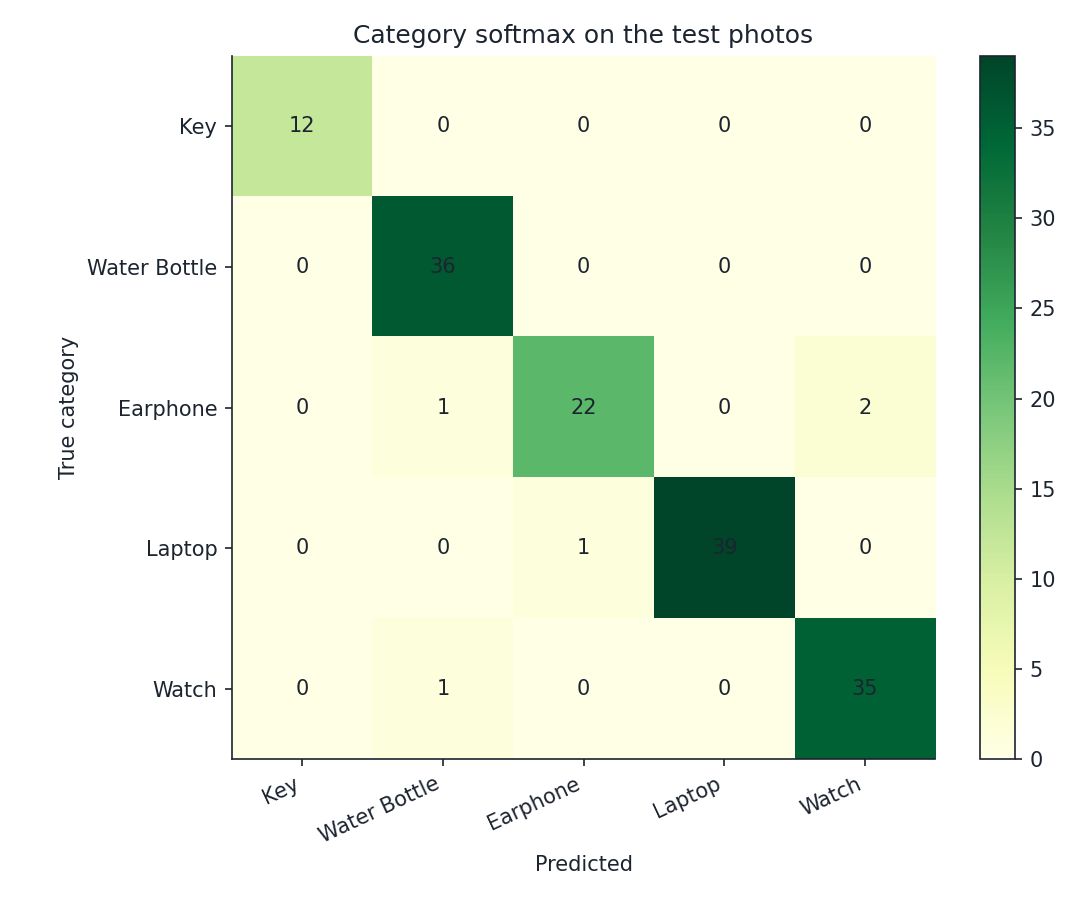

### Linear matcher coefficients

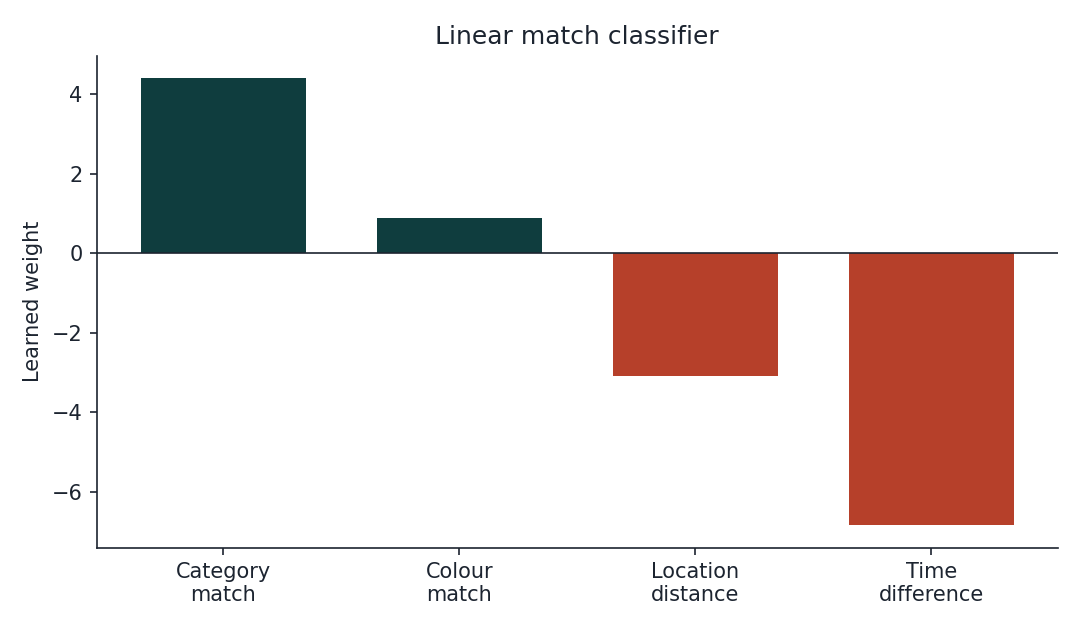

### Recall@5 by method

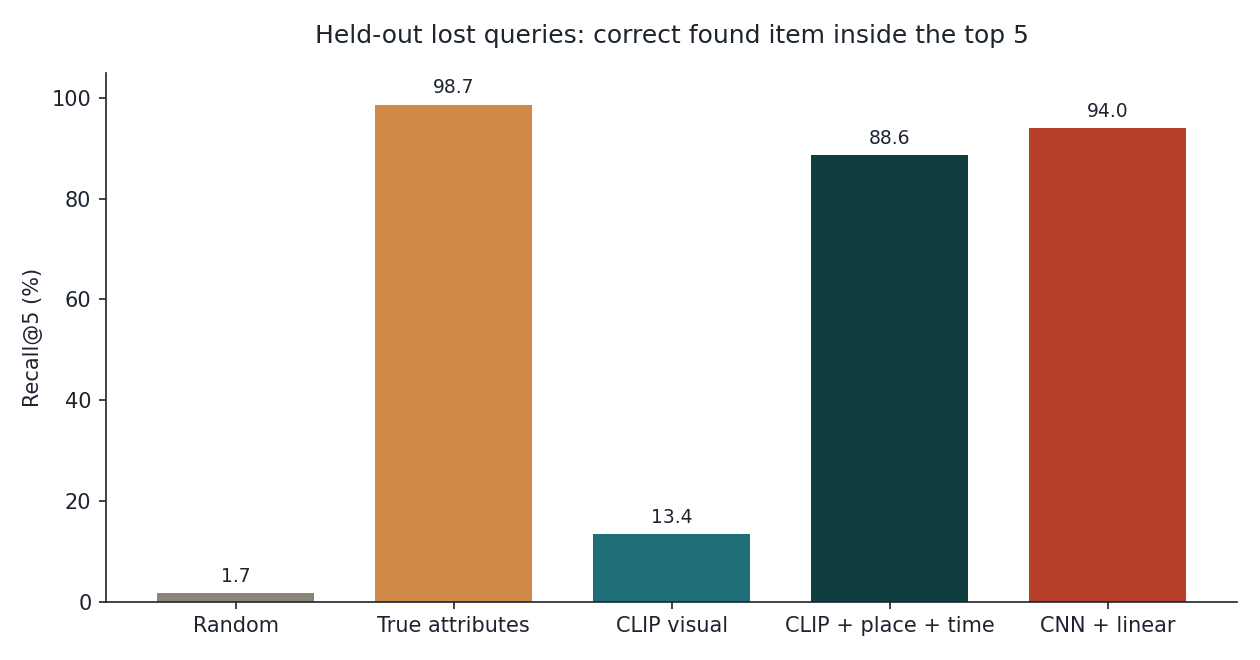

### Recall by category

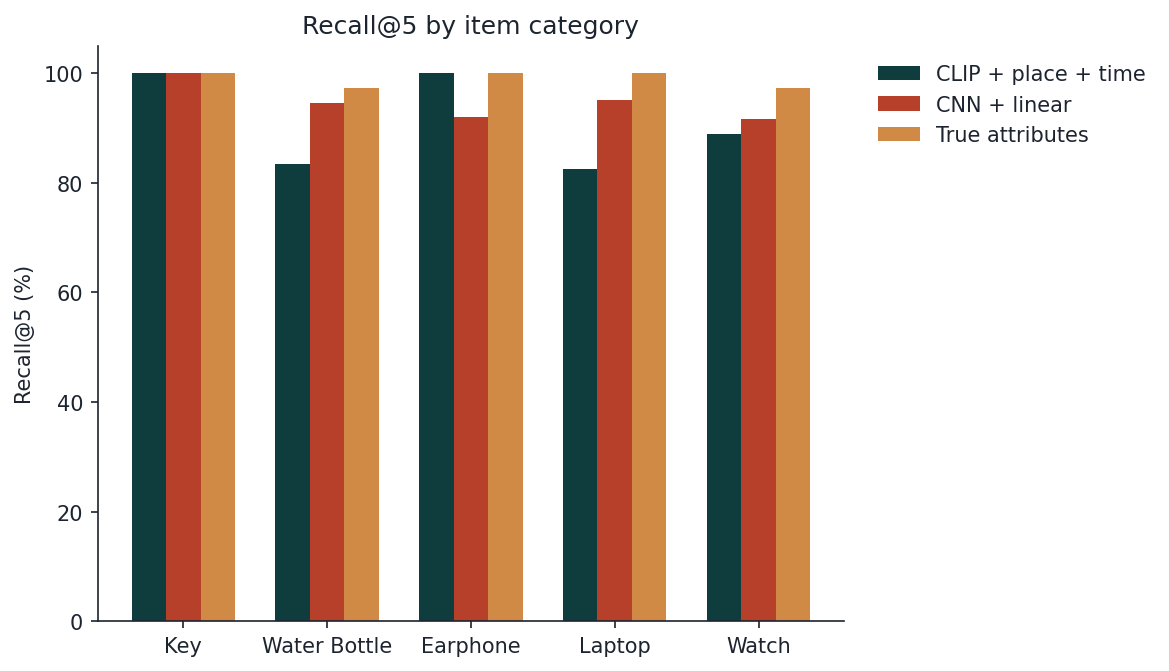

In [8]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    average_precision_score,
    classification_report as sklearn_classification_report,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)
from sklearn.preprocessing import label_binarize


# Evaluation data: gallery should be held out from train_index
eval_records = gallery
X_eval = scaler.transform(cnn_features[gallery_index])

y_category = np.array([record["category"] for record in eval_records])
y_colour = np.array([record["colour"] for record in eval_records])

pred_category_eval = category_model.predict(X_eval)
pred_colour_eval = colour_model.predict(X_eval)

# ------------------------------------------------------------
# 1. PCA scatter plot
# ------------------------------------------------------------
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_eval)

plt.figure(figsize=(9, 7))

for label in sorted(set(y_category)):
    mask = y_category == label
    plt.scatter(
        X_2d[mask, 0],
        X_2d[mask, 1],
        label=label,
        alpha=0.75,
        s=45,
    )

plt.title("PCA scatter plot of image features")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1] * 100:.1f}%)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. Category-colour distribution heat map
# ------------------------------------------------------------
category_labels = list(CATEGORIES)
colour_labels = list(COLOURS)

distribution = np.zeros(
    (len(category_labels), len(colour_labels)),
    dtype=int,
)

for record in eval_records:
    if (
        record["category"] in category_labels
        and record["colour"] in colour_labels
    ):
        row = category_labels.index(record["category"])
        col = colour_labels.index(record["colour"])
        distribution[row, col] += 1

plt.figure(figsize=(10, 6))
plt.imshow(distribution, cmap="YlGnBu", aspect="auto")

plt.xticks(range(len(colour_labels)), colour_labels, rotation=45, ha="right")
plt.yticks(range(len(category_labels)), category_labels)
plt.xlabel("Colour")
plt.ylabel("Category")
plt.title("Category-colour distribution")

for row in range(distribution.shape[0]):
    for col in range(distribution.shape[1]):
        plt.text(
            col,
            row,
            distribution[row, col],
            ha="center",
            va="center",
            color="black",
        )

plt.colorbar(label="Number of images")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Confusion-matrix heat maps
# ------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

ConfusionMatrixDisplay.from_predictions(
    y_category,
    pred_category_eval,
    labels=category_model.classes_,
    display_labels=category_model.classes_,
    cmap="Blues",
    xticks_rotation=45,
    ax=axes[0],
)
axes[0].set_title("Category confusion matrix")

ConfusionMatrixDisplay.from_predictions(
    y_colour,
    pred_colour_eval,
    labels=colour_model.classes_,
    display_labels=colour_model.classes_,
    cmap="Greens",
    xticks_rotation=45,
    ax=axes[1],
)
axes[1].set_title("Colour confusion matrix")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. ROC and precision-recall curves
# ------------------------------------------------------------
def get_scores(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)

    if hasattr(model, "decision_function"):
        scores = model.decision_function(X)

        if scores.ndim == 1:
            scores = np.column_stack([-scores, scores])

        return scores

    raise TypeError(
        f"{type(model).__name__} has neither predict_proba "
        "nor decision_function."
    )


def plot_roc_pr(model, X, y, title):
    classes = np.asarray(model.classes_)
    scores = get_scores(model, X)

    y_binary = label_binarize(y, classes=classes)

    # Binary label_binarize returns only one column.
    if y_binary.shape[1] == 1:
        y_binary = np.column_stack([1 - y_binary[:, 0], y_binary[:, 0]])

    fig, axes = plt.subplots(1, 2, figsize=(15, 6))

    for index, class_name in enumerate(classes):
        fpr, tpr, _ = roc_curve(y_binary[:, index], scores[:, index])
        roc_auc = roc_auc_score(
            y_binary[:, index],
            scores[:, index],
        )

        axes[0].plot(
            fpr,
            tpr,
            label=f"{class_name} (AUC={roc_auc:.3f})",
        )

        precision, recall, _ = precision_recall_curve(
            y_binary[:, index],
            scores[:, index],
        )
        average_precision = average_precision_score(
            y_binary[:, index],
            scores[:, index],
        )

        axes[1].plot(
            recall,
            precision,
            label=f"{class_name} (AP={average_precision:.3f})",
        )

    axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5)
    axes[0].set_title(f"{title} ROC curves")
    axes[0].set_xlabel("False positive rate")
    axes[0].set_ylabel("True positive rate")
    axes[0].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    axes[0].grid(alpha=0.25)

    axes[1].set_title(f"{title} precision-recall curves")
    axes[1].set_xlabel("Recall")
    axes[1].set_ylabel("Precision")
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()


plot_roc_pr(
    category_model,
    X_eval,
    y_category,
    "Category",
)

plot_roc_pr(
    colour_model,
    X_eval,
    y_colour,
    "Colour",
)


# ------------------------------------------------------------
# 5. Numeric classification reports
# ------------------------------------------------------------
print("Category performance")
print(sklearn_classification_report(y_category, pred_category_eval))

print("Colour performance")
print(sklearn_classification_report(y_colour, pred_colour_eval))
def clip_visual_scores(query):
    return visual_of(query)

def clip_fused_scores(query):
    location_close, time_close, _, _ = metadata_arrays(query, gallery)
    fused, _ = clip_fusion(visual_of(query), location_close, time_close, weights)
    return fused

def linear_scores(query):
    _, _, location_far, time_far = metadata_arrays(query, gallery)
    features = np.stack(
        [
            (pred_category == query['category']).astype(np.float32),
            (pred_colour == query['colour']).astype(np.float32),
            location_far,
            time_far,
        ],
        axis=1,
    )
    return linear_probability(features, coefficients, bias)

print('Evaluating...')
splits = {'val': val_queries, 'test': test_queries}
methods = {}
for split_name, queries in splits.items():
    category_counts = dict(Counter(query['category'] for query in queries))
    methods[split_name] = {
        'n_queries': len(queries),
        'gallery_size': len(gallery),
        'methods': {
            'random': random_summary(len(queries), len(gallery), category_counts),
            'metadata_oracle': evaluate(queries, gallery, lambda query: oracle_scores(query, gallery)),
            'clip_visual': evaluate(queries, gallery, clip_visual_scores),
            'clip_fusion': evaluate(queries, gallery, clip_fused_scores),
            'cnn_linear': evaluate(queries, gallery, linear_scores),
        },
    }

classification = project_classification_report(
    scaler,
    category_model,
    colour_model,
    cnn_features,
    records,
    {
        'val': np.array([record_index[record['id']] for record in gallery if record['split'] == 'val']),
        'test': np.array([record_index[record['id']] for record in gallery if record['split'] == 'test']),
    },
)

successes = []
misses = []
for query in test_queries:
    scores = clip_fused_scores(query)
    case = top_case(query, gallery, scores, 'clip_fusion')
    (successes if case['hit_at_5'] else misses).append(case)
successes.sort(key=lambda case: case['rank'])
misses.sort(key=lambda case: case['rank'], reverse=True)
cases = []
seen_categories = set()
for case in successes:
    if case['query']['category'] in seen_categories:
        continue
    seen_categories.add(case['query']['category'])
    cases.append(case)
    if len(cases) == 3:
        break
if misses:
    cases.append(misses[0])

metrics = {
    'group': {
        'course': 'GE2340',
        'group': '26',
        'title': 'Lost-and-Found Image/Text Matcher',
        'members': [
            {'name': 'So Shing Hin', 'id': '59687520'},
            {'name': 'Tu Kwan Yiu', 'id': '60175669'},
            {'name': 'Chan Kai Shun', 'id': '59696515'},
        ],
    },
    'seed': SEED,
    'dataset': {
        'total_photos': len(records),
        'gallery': len(gallery),
        'by_split': dict(Counter(record['split'] for record in records)),
        'by_category': dict(Counter(record['category'] for record in records)),
        'by_colour': dict(Counter(record['colour'] for record in records)),
        'sources': SOURCES,
    },
    'models': {
        'clip': clip.name,
        'cnn': cnn.name,
        'heads': 'Multinomial logistic regression (softmax) on frozen CNN features',
        'matcher': 'Logistic regression on category match, colour match, location distance, and time difference',
    },
    'fusion_weights': {'visual': weights[0], 'location': weights[1], 'time': weights[2]},
    'weight_search': trials,
    'linear_model': {
        'coefficients': {
            'category_match': float(coefficients[0]),
            'colour_match': float(coefficients[1]),
            'location_distance': float(coefficients[2]),
            'time_difference': float(coefficients[3]),
        },
        'bias': bias,
    },
    'classification': classification,
    'val': methods['val'],
    'test': methods['test'],
    'cases': cases,
    'examples': [
        {
            'label': f"{case['query']['colour'].title()} {DISPLAY_CATEGORY[case['query']['category']]}",
            'query': case['query'],
        }
        for case in cases
        if case['hit_at_5']
    ][:3],
}
metrics['findings'] = write_findings(metrics)

dump_json(art / 'gallery.json', [dict(record) for record in gallery])
dump_json(art / 'queries_val.json', val_queries)
dump_json(art / 'queries_test.json', test_queries)
dump_json(art / 'metrics.json', metrics)
dump_json(art / 'backend.json', {'clip': clip.name, 'cnn': cnn.name, 'text_prompt': 'a photo of a {colour} {category}'})
np.savez_compressed(
    art / 'embeddings.npz',
    ids=np.array([record['id'] for record in gallery]),
    clip=clip_images.astype(np.float32),
    text_keys=np.array(text_keys),
    text_vecs=clip_text.astype(np.float32),
)
save_figures(metrics, art / 'figures')
print_table(metrics)
print('Saved artifacts to', art)

from IPython.display import Image, Markdown, display

figure_dir = art / 'figures'
captions = {
    'category_confusion.png': 'Category confusion matrix',
    'linear_weights.png': 'Linear matcher coefficients',
    'recall_at_5.png': 'Recall@5 by method',
    'recall_by_category.png': 'Recall by category',
}
for name, caption in captions.items():
    path = figure_dir / name
    display(Markdown(f'### {caption}'))
    display(Image(filename=str(path)))

